# Phase 7: Technical Premium and Model Diagnostics

**Business question this phase serves:** *what is the expected claims cost (technical premium) per
policy?* The frequency and severity models (Phases 4-6) are combined here, after one improvement Phase 5
pointed to.

**From Phase 5:** the GAM showed that `DrivAge` and `VehAge` have shapes a straight line cannot follow,
and suggested using its curves to re-bin those two factors in an improved GLM, keeping a GLM's
rate-table form. **Section 1 builds that GLM**; it is the frequency model used for the technical premium.

**What this notebook does, in order:**
1. Build the GAM-informed, re-binned frequency GLM (`src/models/frequency_glm_refined.py`) and compare
   it with the Phase 4 GLM and the Phase 5 GAM, out of sample.
2. Combine it with the Phase 6 severity GLM in one scoring pipeline
   (`scoring/score_technical_premium.py`): technical premium = frequency x severity + large-loss
   loading, per policy-year.
3. Diagnostics on the combined technical premium: Gini/Lorenz curve and calibration by decile against
   actual claim cost.
4. Whether the refinement changes the final premium: original vs. refined GLM, same severity model.

## 0. Setup

In [1]:
import sys
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm

warnings.filterwarnings("ignore")


def find_project_root(marker: str = "requirements.txt") -> Path:
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / marker).exists():
            return candidate
    raise FileNotFoundError(f"Could not locate project root (looked for '{marker}' upward from {here})")

PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.features.pipeline import get_frequency_target, get_exposure_offset
from src.models.frequency_glm import fit_poisson_glm
from src.models.frequency_glm_refined import RefinedFeatureEncoder, DRIVAGE_BIN_EDGES, VEHAGE_BIN_EDGES
from src.models.glm_diagnostics import deviance_summary, out_of_sample_pseudo_r2, calibration_by_decile, plot_calibration_by_decile
from src.models.model_comparison import gini_coefficient, lorenz_curve_data, plot_lorenz_curves
from scoring.score_technical_premium import TechnicalPremiumModel, score_technical_premium

pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

train_df = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "train.parquet")
val_df = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "val.parquet")
encoder = joblib.load(PROJECT_ROOT / "models" / "feature_encoder.joblib")
freq_glm_original = joblib.load(PROJECT_ROOT / "models" / "freq_glm.pkl")     # Phase 4
freq_gam = joblib.load(PROJECT_ROOT / "models" / "freq_gam.pkl")             # Phase 5
sev_glm = joblib.load(PROJECT_ROOT / "models" / "sev_glm.pkl")               # Phase 6

print("All Phase 4-6 artifacts loaded.")

All Phase 4-6 artifacts loaded.


## 1. Building the GAM-informed frequency GLM

### 1.1 The evidence: the Phase 5 GAM's fitted curves

Printed from the saved GAM (`models/freq_gam.pkl`), so the bin edges below can be traced to these
numbers.

In [2]:
gam = freq_gam["gam"]

for idx, name in [(0, "DrivAge"), (4, "VehAge_capped")]:
    XX = gam.generate_X_grid(term=idx, n=15)
    pdep, confi = gam.partial_dependence(term=idx, X=XX, width=0.95)
    grid_vals = XX[:, idx]
    relativity = np.exp(pdep - pdep.mean())
    print(f"\n{name} (centered relativity):")
    for g, r in zip(grid_vals, relativity):
        print(f"  {g:7.2f} -> {r:.3f}")


DrivAge (centered relativity):
    18.00 -> 1.595
    23.79 -> 0.746
    29.57 -> 0.566
    35.36 -> 0.677
    41.14 -> 0.921
    46.93 -> 1.039
    52.71 -> 1.001
    58.50 -> 0.915
    64.29 -> 0.865
    70.07 -> 0.893
    75.86 -> 0.980
    81.64 -> 1.094
    87.43 -> 1.243
    93.21 -> 1.442
    99.00 -> 1.683

VehAge_capped (centered relativity):
     0.00 -> 1.184
     1.71 -> 1.218
     3.43 -> 1.279
     5.14 -> 1.282
     6.86 -> 1.254
     8.57 -> 1.235
    10.29 -> 1.206
    12.00 -> 1.141
    13.71 -> 1.033
    15.43 -> 0.900
    17.14 -> 0.802
    18.86 -> 0.768
    20.57 -> 0.753
    22.29 -> 0.711
    24.00 -> 0.647


### 1.2 The bin edges chosen

| Factor | Shape read off the curve above | Bin edges chosen | Bins |
|---|---|---|---|
| `DrivAge` | high at 18, trough near 30, rise to 45-50, dip near 65, rise after 75 (thin data beyond 85) | `[18, 25, 35, 50, 65, 80, 101]` | 18-24, 25-34, 35-49, 50-64, 65-79, 80-100 |
| `VehAge` (capped at 24) | plateau from 0 to about 10 years, then decline | `[0, 11, 15, 19, 25]` | 0-10, 11-14, 15-18, 19-24 |

Each boundary sits near a turning point, so that the GAM's relativity is roughly constant within each
bin, the condition under which a binned GLM term approximates a smooth curve well. Every other factor
is unchanged from Phase 4, `BonusMalus` included (kept linear, as in Phase 4; its shape is examined in
Phase 8).

### 1.3 Fitting

**Compute note:** as in Phases 4-6, full-size fits on this 8GB machine were unreliable, so the refined
GLM is fitted on a stratified 40% sub-sample of the training set (160,470 rows) and validated on the
full validation set like every other model.

In [3]:
from sklearn.model_selection import train_test_split

claim_bucket_train = pd.cut(train_df["ClaimNb_freq_target"], bins=[-1, 0, 1, np.inf], labels=["0", "1", "2+"])
train_sub, _ = train_test_split(train_df, train_size=0.40, stratify=claim_bucket_train, random_state=42)
train_sub = train_sub.reset_index(drop=True)  # required: RefinedFeatureEncoder aligns X/y positionally
print(f"Refined-GLM training sub-sample: {len(train_sub):,} policies ({len(train_sub) / len(train_df):.1%} of train)")

refined_encoder = RefinedFeatureEncoder().fit(train_sub)
X_train_refined = refined_encoder.transform(train_sub)
y_train_sub = get_frequency_target(train_sub)
offset_train_sub = get_exposure_offset(train_sub)

refined_results = fit_poisson_glm(X_train_refined, y_train_sub, offset_train_sub)
print(f"\nRefined GLM: {X_train_refined.shape[1]} feature columns")
print(deviance_summary(refined_results))

Refined-GLM training sub-sample: 160,470 policies (40.0% of train)



Refined GLM: 43 feature columns
{'n_obs': 160470, 'df_model': 43, 'df_resid': 160426, 'log_likelihood': np.float64(-25641.09347993753), 'deviance': np.float64(39228.86508531179), 'null_deviance': np.float64(40946.97593152991), 'aic': np.float64(51370.18695987506), 'pseudo_r2_deviance': np.float64(0.041959407431969686)}


### 1.4 The payoff: does re-binning actually close the gap to the GAM?

In [4]:
# All three models scored on the SAME validation set for a fair, out-of-sample comparison.
X_val_original = encoder.transform(val_df)
X_val_original_const = sm.add_constant(X_val_original[freq_glm_original["feature_columns"]], has_constant="add")
offset_val = get_exposure_offset(val_df)
y_val = get_frequency_target(val_df).to_numpy()
exposure_val = val_df["Exposure"].to_numpy()

pred_original_val = freq_glm_original["results"].predict(X_val_original_const, offset=offset_val)

X_val_refined = refined_encoder.transform(val_df)
X_val_refined_const = sm.add_constant(X_val_refined, has_constant="add")
pred_refined_val = refined_results.predict(X_val_refined_const, offset=offset_val)

X_val_gam = freq_gam["feature_builder"].transform(val_df)
pred_gam_val = gam.predict(X_val_gam, exposure=exposure_val)

rows = []
for name, pred in [("GLM (Phase 4, original)", pred_original_val), ("GLM (refined, this phase)", pred_refined_val), ("GAM (Phase 5)", pred_gam_val)]:
    r2 = out_of_sample_pseudo_r2(y_val, pred, exposure_val)
    gini = gini_coefficient(lorenz_curve_data(y_val, pred, exposure_val))
    rows.append({"model": name, "validation_deviance": r2["model_deviance"], "pseudo_r2": r2["pseudo_r2"], "gini": gini})

comparison = pd.DataFrame(rows)
comparison

,model,validation_deviance,pseudo_r2,gini
0,"GLM (Phase 4, original)","32,563.1879",0.0453,0.2852
1,"GLM (refined, this phase)","32,498.7348",0.0472,0.2945
2,GAM (Phase 5),"32,235.8368",0.0549,0.3105


**Finding:** the refined GLM improves on the original GLM out of sample (pseudo-R² 4.72% vs. 4.53%,
Gini 0.295 vs. 0.285), but closes only part of the gap to the GAM (5.49%, 0.311): about a fifth of the
pseudo-R² gap and a third of the Gini gap. The re-binning of `DrivAge` and `VehAge` is therefore useful
but not where most of the GAM's advantage lies; Phase 8 shows that the rest sits mainly in the shape of
`BonusMalus`. This refined GLM is the frequency model used from here on.

In [5]:
models_dir = PROJECT_ROOT / "models"
joblib.dump({"results": refined_results, "encoder": refined_encoder}, models_dir / "freq_glm_refined.pkl")
print(f"Saved: {(models_dir / 'freq_glm_refined.pkl').relative_to(PROJECT_ROOT).as_posix()}")

Saved: models/freq_glm_refined.pkl


## 2. Technical premium: combining frequency and severity

`scoring/score_technical_premium.py` is the single scoring pipeline, also used by the Streamlit app.
The technical premium is **per policy-year** (an annualized rate): `predicted_frequency x
predicted_severity + large_loss_loading`.

In [6]:
tp_model = TechnicalPremiumModel(
    freq_results=refined_results,
    freq_encoder=refined_encoder,
    sev_results=sev_glm["results"],
    sev_encoder=encoder,
    large_loss_loading=sev_glm["large_loss_loading"],
)

scored_val = score_technical_premium(val_df, tp_model)
print(scored_val.describe())
scored_val.head()

       predicted_frequency  predicted_severity  large_loss_loading  \
count         133,725.0000        133,725.0000        133,725.0000   
mean                0.0786          1,551.2807             33.5351   
std                 0.0647            197.6142              0.0000   
min                 0.0172            625.0709             33.5351   
25%                 0.0515          1,421.3527             33.5351   
50%                 0.0633          1,513.6652             33.5351   
75%                 0.0850          1,645.1103             33.5351   
max                12.8960          2,633.7384             33.5351   

       technical_premium  
count       133,725.0000  
mean            158.0865  
std             127.0217  
min              49.3334  
25%             110.1235  
50%             131.7056  
75%             170.2958  
max          29,576.5332  


,predicted_frequency,predicted_severity,large_loss_loading,technical_premium
0,0.0398,"1,655.9200",33.5351,99.4161
1,0.0669,"1,383.8146",33.5351,126.0638
2,0.0847,"1,555.2841",33.5351,165.2916
3,0.0527,"1,615.0417",33.5351,118.6657
4,0.1140,"1,892.5834",33.5351,249.3604


**Reading:** `predicted_severity` varies little across the book compared with `predicted_frequency`,
consistent with Phase 6 (severity barely differentiates by rating factor). Most of the technical
premium's variation comes from frequency. The maximum predicted frequency (12.9 claims per year) comes
from the linear `BonusMalus` term extrapolated to the highest malus values, a limitation noted for
Phase 8.

## 3. Portfolio diagnostics on the combined technical premium

Compared with **actual claim cost** over each policy's observed exposure (`sev_claim_amount`, 0 for
policies without a claim): `technical_premium x Exposure` is the model's expected cost over that
period.

Technical premium Gini (validation): 0.5801


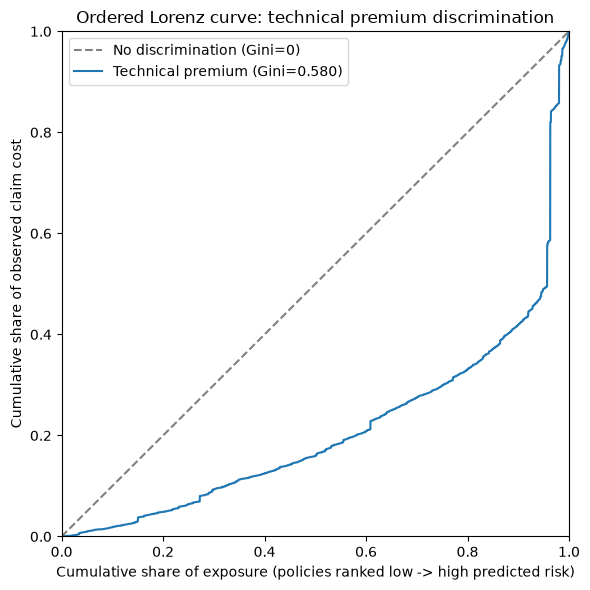

In [7]:
actual_cost_val = val_df["sev_claim_amount"].to_numpy()
predicted_cost_val = scored_val["technical_premium"].to_numpy() * val_df["Exposure"].to_numpy()

lorenz_tp = lorenz_curve_data(actual_cost_val, predicted_cost_val, exposure_val)
gini_tp = gini_coefficient(lorenz_tp)
print(f"Technical premium Gini (validation): {gini_tp:.4f}")

fig = plot_lorenz_curves(
    {"Technical premium": lorenz_tp}, {"Technical premium": gini_tp},
    ylabel="Cumulative share of observed claim cost",
    title="Ordered Lorenz curve: technical premium discrimination",
)
plt.show()

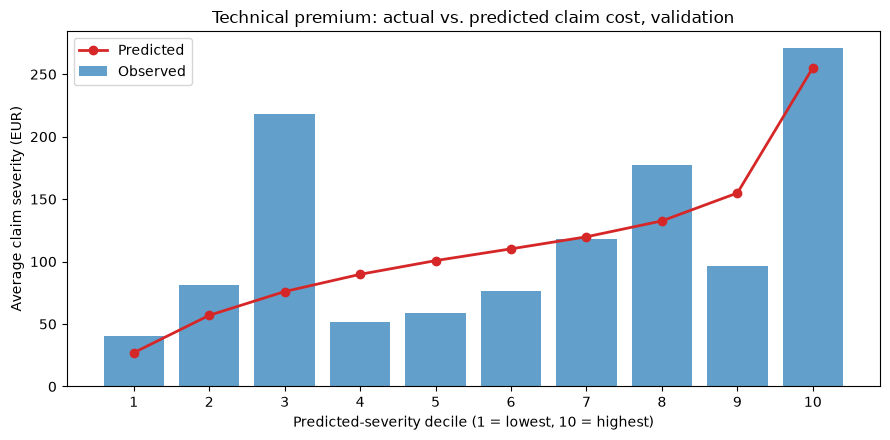

,bin,n_rows,total_weight,observed,predicted
0,1,"48,940.0000","7,088.7468",40.5844,27.0663
1,2,"15,987.0000","7,088.0500",80.8632,56.9847
2,3,"11,283.0000","7,088.8100",217.8565,76.0163
3,4,"9,291.0000","7,089.2900",51.6118,89.8082
4,5,"8,377.0000","7,088.5500",58.7297,100.7800
5,6,"7,926.0000","7,088.7100",76.2658,110.2011
6,7,"7,808.0000","7,089.4400",118.3317,119.8560
7,8,"7,876.0000","7,088.1000",177.0053,132.5786
8,9,"7,974.0000","7,089.3000",96.5568,154.9253
9,10,"8,263.0000","7,089.1100",270.8021,255.2454


In [8]:
decile_tp = calibration_by_decile(actual_cost_val, predicted_cost_val, exposure_val, n_bins=10)
fig = plot_calibration_by_decile(decile_tp, title="Technical premium: actual vs. predicted claim cost, validation")
plt.show()
decile_tp

**Reading:** the technical premium's Gini (0.580) is much higher than the frequency model's (0.295).
This does not mean severity adds predictive signal: the ranking is still driven by predicted
frequency. A Gini on monetary claim cost also reflects how concentrated claim euros are (a small share
of policies with a claim carry all the cost), so the two Ginis are not on the same scale. The
calibration chart orders policies roughly correctly but with noise: decile 3's observed cost is far
above prediction, most likely because a few large claims fell there.

## 4. Does the refinement matter for the *actual premium*, not just for frequency alone?

Section 1 already showed the refined GLM beats the original on frequency metrics. This section asks
the more direct question: holding the *same* severity model fixed, how different is the **final
technical premium** each frequency model produces?

In [9]:
tp_model_original = TechnicalPremiumModel(
    freq_results=freq_glm_original["results"],
    freq_encoder=encoder,
    sev_results=sev_glm["results"],
    sev_encoder=encoder,
    large_loss_loading=sev_glm["large_loss_loading"],
)
scored_val_original = score_technical_premium(val_df, tp_model_original)
predicted_cost_val_original = scored_val_original["technical_premium"].to_numpy() * val_df["Exposure"].to_numpy()

gini_tp_original = gini_coefficient(lorenz_curve_data(actual_cost_val, predicted_cost_val_original, exposure_val))

print(f"Technical premium Gini: original Phase 4 GLM (frequency) + Phase 6 severity: {gini_tp_original:.4f}")
print(f"Technical premium Gini: refined GLM (frequency) + Phase 6 severity:          {gini_tp:.4f}")

premium_correlation = np.corrcoef(scored_val["technical_premium"], scored_val_original["technical_premium"])[0, 1]
print(f"\nCorrelation between the two technical premiums (same policies): {premium_correlation:.4f}")
pct_change = (scored_val["technical_premium"] / scored_val_original["technical_premium"] - 1)
print(f"Median relative change in technical premium from refinement: {pct_change.median():+.2%}")
print(f"10th-90th percentile range of the change: [{pct_change.quantile(0.1):+.2%}, {pct_change.quantile(0.9):+.2%}]")

Technical premium Gini: original Phase 4 GLM (frequency) + Phase 6 severity: 0.5564
Technical premium Gini: refined GLM (frequency) + Phase 6 severity:          0.5801

Correlation between the two technical premiums (same policies): 0.9802
Median relative change in technical premium from refinement: +0.79%
10th-90th percentile range of the change: [-14.45%, +13.13%]


**Finding:** the refinement improves the final technical premium's Gini (0.556 to 0.580), and
individual premiums move by a median of +0.8% (10th to 90th percentile: -14% to +13%), since `DrivAge`
and `VehAge` apply to every policy.

## 5. Summary

In [10]:
summary = pd.DataFrame(
    [
        {"stage": "Frequency: original GLM (Phase 4)", "gini": comparison.loc[0, "gini"], "pseudo_r2": comparison.loc[0, "pseudo_r2"]},
        {"stage": "Frequency: refined GLM (this phase)", "gini": comparison.loc[1, "gini"], "pseudo_r2": comparison.loc[1, "pseudo_r2"]},
        {"stage": "Frequency: GAM (Phase 5, benchmark only)", "gini": comparison.loc[2, "gini"], "pseudo_r2": comparison.loc[2, "pseudo_r2"]},
        {"stage": "Technical premium: original GLM + severity", "gini": gini_tp_original, "pseudo_r2": np.nan},
        {"stage": "Technical premium: refined GLM + severity (FINAL)", "gini": gini_tp, "pseudo_r2": np.nan},
    ]
)
summary

,stage,gini,pseudo_r2
0,Frequency: original GLM (Phase 4),0.2852,0.0453
1,Frequency: refined GLM (this phase),0.2945,0.0472
2,"Frequency: GAM (Phase 5, benchmark only)",0.3105,0.0549
3,Technical premium: original GLM + severity,0.5564,NaN
4,Technical premium: refined GLM + severity (FINAL),0.5801,NaN


## Phase 7 summary

| Check | Result |
|---|---|
| GAM-informed re-binning | `DrivAge` in 6 bins, `VehAge` in 4 bins, edges read off the Phase 5 GAM curves |
| Refined GLM vs. original GLM (validation) | Pseudo-R² 4.72% vs. 4.53%; Gini 0.295 vs. 0.285 |
| Refined GLM vs. GAM (validation) | GAM still ahead (5.49%, 0.311); the remaining gap is mainly `BonusMalus` (Phase 8) |
| Technical premium formula | `predicted_frequency (refined GLM) x predicted_severity (Phase 6 GLM) + large_loss_loading` |
| Technical premium Gini (validation) | 0.580, on a monetary scale, not comparable with a frequency Gini |
| Refinement's downstream impact | Gini 0.556 to 0.580; median premium change +0.8% (10th-90th percentile: -14% to +13%) |

**Output:** [`models/freq_glm_refined.pkl`](../models/freq_glm_refined.pkl),
[`scoring/score_technical_premium.py`](../scoring/score_technical_premium.py), ready for
**Phase 8: portfolio KPIs (Loss Ratio, COR, ATP)**.